<a href="https://colab.research.google.com/github/JyRaGa/CS303-Machine-Learning_Coursework/blob/main/exp12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS303 Machine Learning Lab
## Experiment No. 12: Multilayer Perceptron Training, Regularisation and Learning Curves
### Roll No: 24/CS/232

---

### **Aim:**
To implement a **Multilayer Perceptron (MLP)** classifier and study the effects of **learning rate**, **network architecture**, **L2 regularisation** and **early stopping** on training convergence, overfitting and test performance.

### **Objectives:**
After completing this experiment, students will be able to:
1. Understand the **structure** of a Multilayer Perceptron.
2. **Train** an MLP classifier using Scikit-learn.
3. Understand how **backpropagation** updates network weights.
4. Investigate the effect of different **learning rates** on training loss.
5. Compare **shallow, deep and wider** network architectures.
6. Understand **L2 regularisation** through the `alpha` parameter.
7. Apply **early stopping** to reduce overfitting.
8. **Plot and interpret** training loss and validation performance.
9. Compare **training and test accuracy** to assess generalisation.
10. **Recommend** a suitable MLP configuration based on experimental evidence.

### **Pseudo Algorithm / Steps:**
1. **Start**.
2. **Load** the Breast Cancer Wisconsin dataset.
3. **Separate** numerical features and the binary target.
4. **Divide** the dataset into training and testing sets.
5. **Standardize** features using statistics calculated from the training set.
6. **Train** a baseline MLP classifier.
7. **Record** test accuracy and the training loss curve.
8. **Train** models using different learning rates.
9. **Compare** architectures with different numbers and widths of hidden layers.
10. **Apply** L2 regularisation using different alpha values.
11. **Enable** early stopping and inspect validation scores.
12. **Compare** training and test performance.
13. **Recommend** a final configuration based on convergence and generalisation.
14. **Stop**.

**1. Loading the Dataset & Separating Features and Target (Steps 2–3)**

* **Dataset:** Breast Cancer Wisconsin (Diagnostic), loaded with `load_breast_cancer(as_frame=True)`; it is the same UCI data hosted on Kaggle, so no upload or login is needed in Colab.
* **Features:** 30 numerical features (mean, standard error and worst value of 10 cell-nucleus measurements).
* **Target:** `target` (0 = malignant, 1 = benign) $\rightarrow$ **Binary Classification Task**.

In [1]:
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')
data = load_breast_cancer(as_frame=True)  # same uci data as the kaggle one
df = data.frame
print('shape:', df.shape)
print('missing values:', df.isnull().sum().sum())
X = df.drop(columns=['target'])
y = df['target']
print('numerical features:', X.shape[1])
print('class counts:', y.value_counts().to_dict(), '(0 = malignant, 1 = benign)')

shape: (569, 31)
missing values: 0
numerical features: 30
class counts: {1: 357, 0: 212} (0 = malignant, 1 = benign)


**2. Train-Test Split & Standardization (Steps 4–5)**

* **Split:** 80/20, stratified so both sets keep the same malignant/benign ratio.
* **Scaling:** `StandardScaler` is fitted on the **training set only** and then applied to the test set, so no test information leaks into training.
* MLPs use gradient descent, and features on very different scales (e.g. `mean area` ~ 1000 vs `mean smoothness` ~ 0.1) make the loss surface badly shaped and slow down training.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)  # fit on train only
X_test_s = scaler.transform(X_test)
print('train shape:', X_train_s.shape, '| test shape:', X_test_s.shape)
print(f'train mean (max abs): {np.abs(X_train_s.mean(axis=0)).max():.2e}')
print(f'test mean range     : {X_test_s.mean(axis=0).min():.3f} '
      f'to {X_test_s.mean(axis=0).max():.3f}')

train shape: (455, 30) | test shape: (114, 30)
train mean (max abs): 8.74e-16
test mean range     : -0.135 to 0.131


**3. Baseline MLP $(32, 16)$, Test Accuracy & Training Loss Curve (Steps 6–7)**

* **Structure:** 30 inputs $\rightarrow$ 32 ReLU neurons $\rightarrow$ 16 ReLU neurons $\rightarrow$ 1 logistic output; each layer computes $a = f(Wx + b)$.
* **Training:** `solver='adam'`, `learning_rate_init=0.001`, minimising **log-loss** (binary cross-entropy) for up to 500 epochs.
* `loss_curve_` stores the training loss after every epoch; `n_iter_` gives the epochs actually used before convergence.
* A helper `fit_mlp()` is reused for every later experiment so all runs are trained the same way.

BASELINE MLP (32, 16), LR = 0.001
layer sizes         : [30, 32, 16, 1]
trainable params    : 1537
epochs used         : 295
final train loss    : 0.0053
train accuracy      : 1.0000
test accuracy       : 0.9561


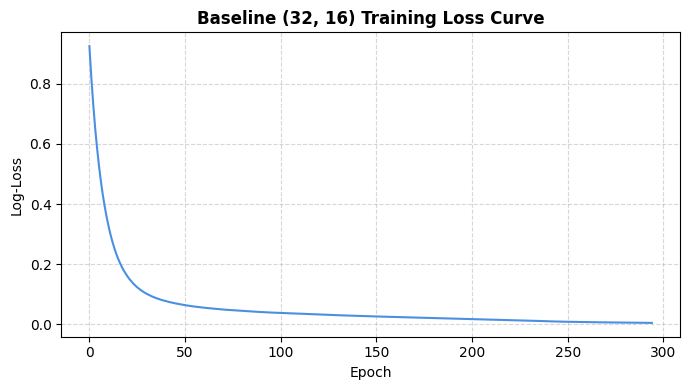

In [3]:
def fit_mlp(**params):
    cfg = dict(hidden_layer_sizes=(32, 16), learning_rate_init=0.001,
               max_iter=500, random_state=42)
    cfg.update(params)
    m = MLPClassifier(**cfg).fit(X_train_s, y_train)
    tr = accuracy_score(y_train, m.predict(X_train_s))
    te = accuracy_score(y_test, m.predict(X_test_s))
    return m, tr, te
base, base_tr, base_te = fit_mlp()
n_params = sum(w.size for w in base.coefs_) + sum(b.size for b in base.intercepts_)
print('=' * 50)
print('BASELINE MLP (32, 16), LR = 0.001')
print('=' * 50)
print(f'layer sizes         : {[30] + list(base.hidden_layer_sizes) + [1]}')
print(f'trainable params    : {n_params}')
print(f'epochs used         : {base.n_iter_}')
print(f'final train loss    : {base.loss_curve_[-1]:.4f}')
print(f'train accuracy      : {base_tr:.4f}')
print(f'test accuracy       : {base_te:.4f}')
print('=' * 50)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(base.loss_curve_, color='#4a90e2')
ax.set_title('Baseline (32, 16) Training Loss Curve', fontsize=12,
             fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Log-Loss')
ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**4. How Backpropagation Updates the Weights (Objective 3)**

### **Theoretical Background:**
$$W^{(l)} \leftarrow W^{(l)} - \eta \, \frac{\partial L}{\partial W^{(l)}}, \qquad \delta^{(l)} = \left(W^{(l+1)T} \delta^{(l+1)}\right) \odot f'(z^{(l)})$$

Where:
* $\eta$ is the **learning rate** and $L$ the log-loss.
* $\delta^{(l)}$ is the error signal of layer $l$, passed **backwards** from the output layer using the chain rule.
* $f'(z^{(l)})$ is the derivative of the activation (ReLU) at that layer.

* A fresh $(32, 16)$ network is trained one epoch at a time with `partial_fit()`; the loss and the size of the weight change in each layer are printed to show backpropagation at work.

In [4]:
bp = MLPClassifier(hidden_layer_sizes=(32, 16), learning_rate_init=0.001,
                   random_state=42)
bp.partial_fit(X_train_s, y_train, classes=[0, 1])
print('weight matrix shapes:', [w.shape for w in bp.coefs_])
for epoch in range(2, 6):
    old = [w.copy() for w in bp.coefs_]
    bp.partial_fit(X_train_s, y_train)
    change = [np.abs(w - o).mean() for w, o in zip(bp.coefs_, old)]  # per layer
    print(f'epoch {epoch} | loss {bp.loss_:.4f} | mean |dW| per layer:',
          [f'{c:.5f}' for c in change])

weight matrix shapes: [(30, 32), (32, 16), (16, 1)]
epoch 2 | loss 0.8220 | mean |dW| per layer: ['0.00246', '0.00248', '0.00257']
epoch 3 | loss 0.7324 | mean |dW| per layer: ['0.00236', '0.00241', '0.00248']
epoch 4 | loss 0.6540 | mean |dW| per layer: ['0.00229', '0.00232', '0.00241']
epoch 5 | loss 0.5861 | mean |dW| per layer: ['0.00219', '0.00223', '0.00243']


**5. Effect of Learning Rate (Step 8)**

* Three learning rates from the PDF are tried on the baseline $(32, 16)$ network: $\eta = 0.0001$, $0.001$ and $0.1$.
* A **too small** rate takes tiny steps and may not converge within 500 epochs; a **too large** rate overshoots the minimum, so the loss can jump around.
* Loss curves are drawn on one plot (log scale) to compare convergence speed and stability.

lr = 0.0001  | epochs 500 | final loss 0.0629 | loss rises  0 | train 0.9890 | test 0.9825
lr = 0.001   | epochs 295 | final loss 0.0053 | loss rises  0 | train 1.0000 | test 0.9561
lr = 0.1     | epochs  42 | final loss 0.0072 | loss rises  9 | train 0.9978 | test 0.9386


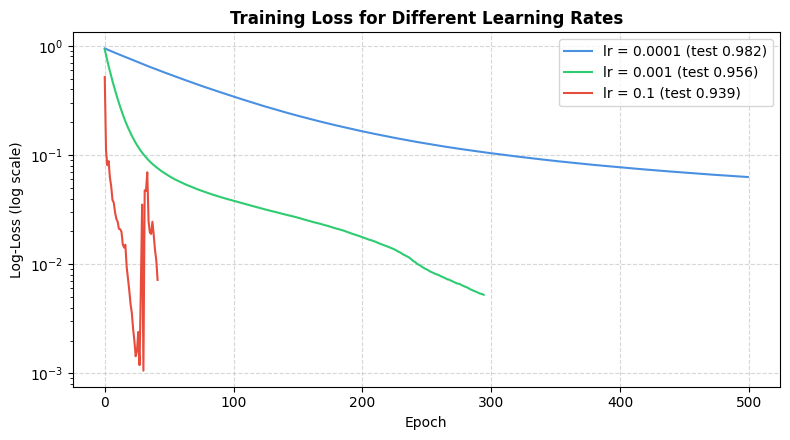

In [5]:
lr_res = {}
for lr in [0.0001, 0.001, 0.1]:
    m, tr, te = fit_mlp(learning_rate_init=lr)
    lr_res[lr] = (m, tr, te)
    jumps = int((np.diff(m.loss_curve_) > 0).sum())  # epochs where loss went up
    print(f'lr = {lr:<7} | epochs {m.n_iter_:>3} | final loss '
          f'{m.loss_curve_[-1]:.4f} | loss rises {jumps:>2} | '
          f'train {tr:.4f} | test {te:.4f}')
colors = ['#4a90e2', '#2ecc71', '#e74c3c']
fig, ax = plt.subplots(figsize=(8, 4.5))
for (lr, (m, tr, te)), c in zip(lr_res.items(), colors):
    ax.plot(m.loss_curve_, color=c, label=f'lr = {lr} (test {te:.3f})')
ax.set_yscale('log')
ax.set_title('Training Loss for Different Learning Rates', fontsize=12,
             fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Log-Loss (log scale)')
ax.legend()
ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**6. Comparing Architectures by Adding Hidden Layers (Step 9)**

* Input (30 neurons) and output (1 neuron) layers stay the same; only the **hidden layers** are changed, one layer added at a time.
* **1 hidden layer:** $(16,)$ $\rightarrow$ 30-16-1, a shallow network.
* **2 hidden layers:** $(16, 32)$ $\rightarrow$ 30-16-32-1, a wider second layer is added.
* **3 hidden layers:** $(16, 32, 16)$ $\rightarrow$ 30-16-32-16-1, the deepest network.
* All use $\eta = 0.001$; parameter count, epochs and accuracies are compared after each step.

(16,)         | params   513 | epochs 367 | train 0.9912 | test 0.9649 | gap +0.0263
(16, 32)      | params  1073 | epochs 249 | train 1.0000 | test 0.9649 | gap +0.0351
(16, 32, 16)  | params  1585 | epochs 200 | train 1.0000 | test 0.9561 | gap +0.0439


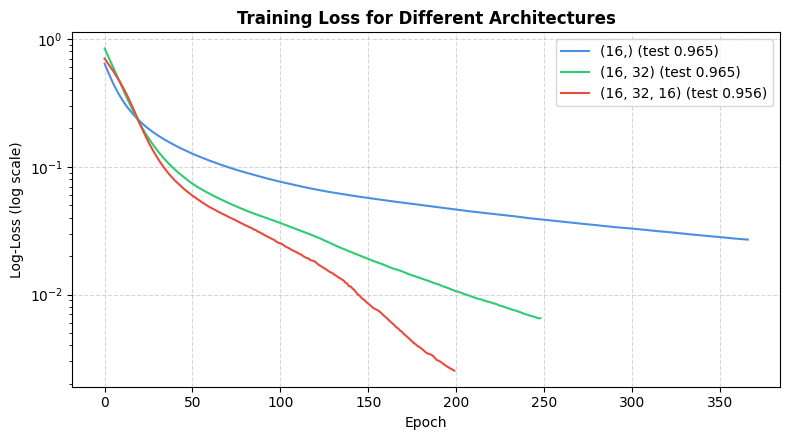

In [6]:
arch_res = {}
for arch in [(16,), (16, 32), (16, 32, 16)]:
    m, tr, te = fit_mlp(hidden_layer_sizes=arch)
    arch_res[arch] = (m, tr, te)
    n_p = sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)
    print(f'{str(arch):<13} | params {n_p:>5} | epochs {m.n_iter_:>3} | '
          f'train {tr:.4f} | test {te:.4f} | gap {tr - te:+.4f}')
fig, ax = plt.subplots(figsize=(8, 4.5))
for (arch, (m, tr, te)), c in zip(arch_res.items(), colors):
    ax.plot(m.loss_curve_, color=c, label=f'{arch} (test {te:.3f})')
ax.set_yscale('log')
ax.set_title('Training Loss for Different Architectures', fontsize=12,
             fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Log-Loss (log scale)')
ax.legend()
ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**7. L2 Regularisation with Different `alpha` Values (Step 10)**

* `alpha` adds an L2 penalty to the loss: $L_{reg} = L + \frac{\alpha}{2n} \sum \lVert W \rVert^2$, so large weights are punished.
* Values $\alpha = 0.0001$ (sklearn default), $0.01$, $1$ and $10$ are tried on the $(32, 16)$ network.
* The total weight norm $\sum \lVert W \rVert^2$ shows how strongly the weights shrink as `alpha` grows.

In [7]:
alpha_res = {}
for a in [0.0001, 0.01, 1, 10]:
    m, tr, te = fit_mlp(alpha=a)
    alpha_res[a] = (m, tr, te)
    w_norm = sum((w ** 2).sum() for w in m.coefs_)
    print(f'alpha = {a:<6} | weight norm {w_norm:>8.2f} | epochs {m.n_iter_:>3} | '
          f'train {tr:.4f} | test {te:.4f} | gap {tr - te:+.4f}')

alpha = 0.0001 | weight norm    86.61 | epochs 295 | train 1.0000 | test 0.9561 | gap +0.0439
alpha = 0.01   | weight norm    79.38 | epochs 296 | train 1.0000 | test 0.9561 | gap +0.0439
alpha = 1      | weight norm    12.20 | epochs 423 | train 0.9912 | test 0.9561 | gap +0.0351
alpha = 10     | weight norm     3.80 | epochs 377 | train 0.9824 | test 0.9649 | gap +0.0175


**8. Early Stopping & Validation Scores (Step 11)**

* `early_stopping=True` holds out 10% of the training data as a **validation set** and stops when the validation accuracy has not improved for `n_iter_no_change=10` epochs.
* `validation_scores_` gives the validation accuracy per epoch, and `best_validation_score_` the best one; the weights from the best epoch are kept.
* Training loss and validation accuracy are plotted side by side as **learning curves** (Objective 8).

EARLY STOPPING (32, 16), LR = 0.001
stopped at epoch    : 25 (baseline used 295)
best val epoch      : 14
best val accuracy   : 0.9565
train accuracy      : 0.9495
test accuracy       : 0.9211


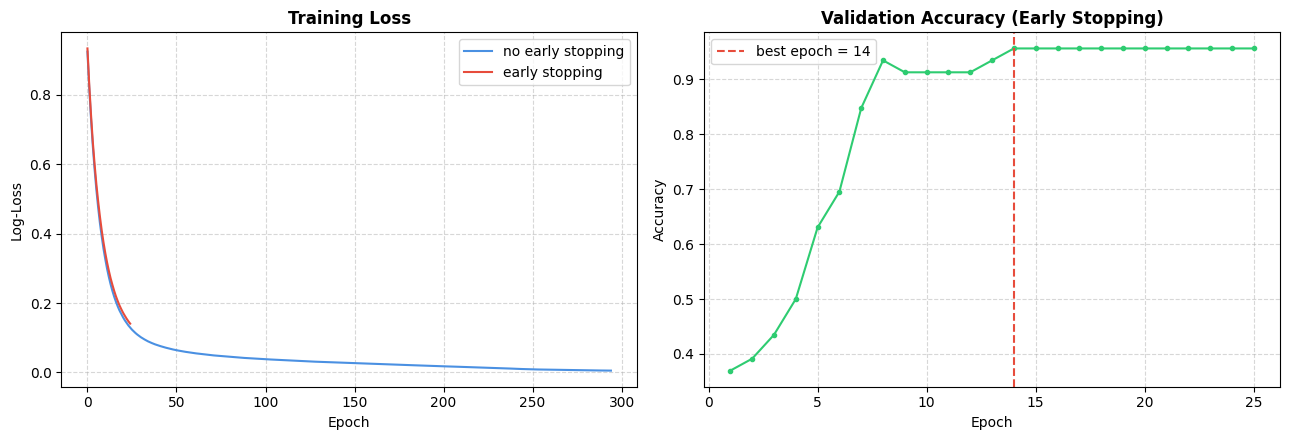

In [8]:
es, es_tr, es_te = fit_mlp(early_stopping=True, validation_fraction=0.1,
                           n_iter_no_change=10)
best_ep = int(np.argmax(es.validation_scores_)) + 1
print('=' * 50)
print('EARLY STOPPING (32, 16), LR = 0.001')
print('=' * 50)
print(f'stopped at epoch    : {es.n_iter_} (baseline used {base.n_iter_})')
print(f'best val epoch      : {best_ep}')
print(f'best val accuracy   : {es.best_validation_score_:.4f}')
print(f'train accuracy      : {es_tr:.4f}')
print(f'test accuracy       : {es_te:.4f}')
print('=' * 50)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(base.loss_curve_, color='#4a90e2', label='no early stopping')
axes[0].plot(es.loss_curve_, color='#e74c3c', label='early stopping')
axes[0].set_title('Training Loss', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Log-Loss')
axes[1].plot(range(1, len(es.validation_scores_) + 1), es.validation_scores_,
             'o-', color='#2ecc71', markersize=3)
axes[1].axvline(best_ep, color='#e74c3c', linestyle='--',
                label=f'best epoch = {best_ep}')
axes[1].set_title('Validation Accuracy (Early Stopping)', fontsize=12,
                  fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
for ax in axes:
    ax.legend()
    ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**9. Observation Table: Training vs Test Performance (Step 12)**

* The table uses the PDF's columns and rows; every accuracy and every observation is generated from the runs above.
* `Gap (Train - Test)` is added to judge **overfitting** (large positive gap) or **underfitting** (both accuracies low).
* The observation text is built in code from epochs used, loss rises, gap and stopping epoch.

In [9]:
def note(m, tr, te):
    rises = int((np.diff(m.loss_curve_) > 0).sum())
    if m.n_iter_ >= 500:
        txt = 'not converged in 500 epochs'
    else:
        txt = f'converged in {m.n_iter_} epochs'
    if rises > 5:
        txt += f', loss rose {rises}x (unstable)'
    if tr - te > 0.03:
        txt += ', overfits'
    elif tr < 0.95:
        txt += ', underfits'
    return txt
rows = [('Baseline', '(32, 16), LR 0.001', base, base_tr, base_te)]
for lr in [0.0001, 0.001, 0.1]:
    rows.append(('Learning rate', str(lr), *lr_res[lr]))
for arch in [(16,), (16, 32), (16, 32, 16)]:
    rows.append(('Architecture', str(arch), *arch_res[arch]))
rows.append(('Regularisation', 'alpha = 0.01', *alpha_res[0.01]))
obs = [[e, p, tr, te, tr - te, note(m, tr, te)] for e, p, m, tr, te in rows]
obs.append(['Early stopping', 'Enabled', es_tr, es_te, es_tr - es_te,
            f'stopped at epoch {es.n_iter_}, best val epoch {best_ep}'])
obs_df = pd.DataFrame(obs, columns=['Experiment', 'Parameter', 'Training accuracy',
                                    'Test accuracy', 'Gap (Train - Test)',
                                    'Observation'])
print(obs_df.round(4).to_string(index=False))

    Experiment          Parameter  Training accuracy  Test accuracy  Gap (Train - Test)                                               Observation
      Baseline (32, 16), LR 0.001             1.0000         0.9561              0.0439                         converged in 295 epochs, overfits
 Learning rate             0.0001             0.9890         0.9825              0.0066                               not converged in 500 epochs
 Learning rate              0.001             1.0000         0.9561              0.0439                         converged in 295 epochs, overfits
 Learning rate                0.1             0.9978         0.9386              0.0592 converged in 42 epochs, loss rose 9x (unstable), overfits
  Architecture              (16,)             0.9912         0.9649              0.0263                                   converged in 367 epochs
  Architecture           (16, 32)             1.0000         0.9649              0.0351                         converged in

**10. Recommending a Final Configuration with Cross-Validation (Step 13)**

* The final choice is made by **5-fold stratified cross-validation** on the training set, not by test accuracy, so the test set stays unseen.
* A `Pipeline` of `StandardScaler` + `MLPClassifier` is used inside `GridSearchCV`, so scaling is re-fitted on each training fold (no leakage).
* The grid combines the architectures, learning rates and `alpha` values studied above, with early stopping on.

In [10]:
pipe = Pipeline([('scaler', StandardScaler()),
                 ('mlp', MLPClassifier(max_iter=500, early_stopping=True,
                                       random_state=42))])
grid = {'mlp__hidden_layer_sizes': [(16,), (16, 32), (16, 32, 16)],
        'mlp__learning_rate_init': [0.001, 0.01],
        'mlp__alpha': [0.0001, 0.01, 1]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
gs = GridSearchCV(pipe, grid, cv=cv, scoring='accuracy', n_jobs=-1)
gs.fit(X_train, y_train)  # raw data, pipeline scales per fold
res = pd.DataFrame(gs.cv_results_)
cols = ['param_mlp__hidden_layer_sizes', 'param_mlp__learning_rate_init',
        'param_mlp__alpha', 'mean_test_score', 'std_test_score']
top = res.sort_values('rank_test_score')[cols].head(5)
top.columns = ['architecture', 'lr', 'alpha', 'cv mean acc', 'cv std']
print(top.round(4).to_string(index=False))
best_model = gs.best_estimator_
fin_tr = accuracy_score(y_train, best_model.predict(X_train))
fin_te = accuracy_score(y_test, best_model.predict(X_test))
print('=' * 50)
print('RECOMMENDED MLP CONFIGURATION')
print('=' * 50)
for k, v in gs.best_params_.items():
    print(f'{k.replace("mlp__", ""):<20}: {v}')
print(f'cv accuracy         : {gs.best_score_:.4f}')
print(f'train accuracy      : {fin_tr:.4f}')
print(f'test accuracy       : {fin_te:.4f}')
print('=' * 50)

architecture   lr  alpha  cv mean acc  cv std
(16, 32, 16) 0.01 1.0000       0.9758  0.0128
       (16,) 0.01 0.0001       0.9692  0.0162
       (16,) 0.01 0.0100       0.9692  0.0162
       (16,) 0.01 1.0000       0.9692  0.0128
(16, 32, 16) 0.01 0.0100       0.9648  0.0189
RECOMMENDED MLP CONFIGURATION
alpha               : 1
hidden_layer_sizes  : (16, 32, 16)
learning_rate_init  : 0.01
cv accuracy         : 0.9758
train accuracy      : 0.9758
test accuracy       : 0.9561


### **Performance Summary & Comparison Table:**

| Experiment | Parameter | Training accuracy | Test accuracy | Gap (Train - Test) |
| :--- | :---: | :---: | :---: | :---: |
| **Baseline** | (32, 16), LR 0.001 | 1.0000 | 0.9561 | 0.0439 |
| **Learning rate** | 0.0001 | 0.9890 | 0.9825 | 0.0066 |
| **Learning rate** | 0.001 | 1.0000 | 0.9561 | 0.0439 |
| **Learning rate** | 0.1 | 0.9978 | 0.9386 | 0.0592 |
| **Architecture** | (16,) | 0.9912 | 0.9649 | 0.0263 |
| **Architecture** | (16, 32) | 1.0000 | 0.9649 | 0.0351 |
| **Architecture** | (16, 32, 16) | 1.0000 | 0.9561 | 0.0439 |
| **Regularisation** | alpha = 0.01 | 1.0000 | 0.9561 | 0.0439 |
| **Early stopping** | Enabled | 0.9495 | 0.9211 | 0.0284 |
| **Recommended (CV)** | (16, 32, 16), LR 0.01, alpha 1, early stopping | 0.9758 | 0.9561 | 0.0197 |

*Note: with only 114 test rows, one misclassified tumour changes test accuracy by about 0.0088, so small differences between rows are within noise.*

---

### **Observations:**
* **Backpropagation:** in the first epochs every layer's weights move by about 0.002 per step while the loss falls from 0.8220 to 0.5861, showing the error gradient reaching all three weight matrices.
* **Convergence Speed:** $\eta = 0.0001$ had not converged after 500 epochs (final loss 0.0629), $\eta = 0.001$ converged in 295 epochs (loss 0.0053) and $\eta = 0.1$ stopped in only 42 epochs.
* **Stability:** with $\eta = 0.1$ the training loss went **up** 9 times and the test accuracy dropped to 0.9386, a sign of oscillating, unstable optimisation; the two smaller rates had 0 loss rises.
* **Architecture:** adding hidden layers one at a time, $(16,)$ $\rightarrow$ $(16, 32)$ $\rightarrow$ $(16, 32, 16)$, grew the parameters from 513 to 1073 to 1585 and cut the epochs needed from 367 to 249 to 200, but test accuracy went 0.9649 $\rightarrow$ 0.9649 $\rightarrow$ 0.9561 while the gap grew from 0.0263 to 0.0439; without regularisation, extra layers only memorised the training set.
* **L2 Regularisation:** raising `alpha` from 0.0001 to 10 shrank the total weight norm from 86.61 to 3.80 and cut the train-test gap from 0.0439 to 0.0175; `alpha = 0.01` was too weak to change anything (norm 79.38, same accuracies).
* **Early Stopping:** with $\eta = 0.001$ training stopped at epoch 25 (best validation epoch 14, validation accuracy 0.9565) instead of 295, which avoided memorising the data but stopped too early here (test 0.9211), i.e. slight **underfitting**.

---

### **Conclusion:**
* **MLP Performance:** a $(32, 16)$ MLP on standardized features classifies breast tumours with 0.9561 test accuracy, but reaches 1.0000 training accuracy, so the unregularised baseline overfits.
* **Effect of Learning Rate:** $\eta$ controls the trade-off between speed and stability: 0.0001 is too slow (not converged in 500 epochs) and 0.1 is unstable (9 loss rises, lowest test accuracy 0.9386).
* **Effect of Capacity & Regularisation:** on their own, extra hidden layers overfit 455 training rows; a strong L2 penalty ($\alpha = 1$ to $10$) reins the weights in and reduces the overfitting gap.
* **Recommended Configuration:** 5-fold CV selected **three hidden layers `(16, 32, 16)`, `learning_rate_init = 0.01`, `alpha = 1`, early stopping on** (CV accuracy 0.9758, best of 18 combinations). The deep network only wins once L2 and early stopping control it: it gives 0.9758 train and 0.9561 test accuracy, a gap of 0.0197 compared with 0.0439 for the same layers unregularised.

**Saving the Recommended Model**

* The full pipeline (scaler + MLP) from `GridSearchCV` is saved with `joblib`, as Joblib / Pickle is listed in the PDF's libraries.

In [11]:
joblib.dump(best_model, 'mlp_breast_cancer_model.pkl')
loaded_model = joblib.load('mlp_breast_cancer_model.pkl')
print('model saved and reloaded, test accuracy:',
      round(accuracy_score(y_test, loaded_model.predict(X_test)), 4))

model saved and reloaded, test accuracy: 0.9561


**11. Viva Questions & Comprehensive Answers**

### **Q1. What is an MLP?**
**Answer:** A **Multilayer Perceptron** is a feed-forward neural network with an input layer, one or more **hidden layers** and an output layer, where every neuron is fully connected to the next layer. Each neuron computes a weighted sum plus bias and passes it through a **non-linear activation** (ReLU here), $a = f(Wx + b)$. The non-linearity lets the MLP learn curved decision boundaries that a single perceptron cannot. In this experiment the baseline MLP had layers $[30, 32, 16, 1]$ and 1537 trainable parameters.

---

### **Q2. What is backpropagation?**
**Answer:** **Backpropagation** is the algorithm that computes the gradient of the loss with respect to every weight using the **chain rule**. After a forward pass, the output error is passed backwards layer by layer, $\delta^{(l)} = (W^{(l+1)T} \delta^{(l+1)}) \odot f'(z^{(l)})$, and each weight gradient is $\delta^{(l)} a^{(l-1)T}$. An optimiser (Adam here) then updates the weights against the gradient. The `partial_fit` run showed all three weight matrices changing every epoch while the loss fell from 0.8220 to 0.5861.

---

### **Q3. What is the learning rate?**
**Answer:** The **learning rate** $\eta$ (`learning_rate_init`) is the step size of each weight update, $W \leftarrow W - \eta \nabla_W L$. It decides how far the weights move along the gradient in one step. It is the most important hyperparameter for **convergence**: too small is slow, too large is unstable. In this lab $\eta = 0.001$ converged in 295 epochs, while 0.0001 and 0.1 behaved very differently.

---

### **Q4. What happens when the learning rate is too low?**
**Answer:** With a very small $\eta$ the weights move in **tiny steps**, so training is very slow and may stop at `max_iter` before reaching the minimum. It can also get stuck longer in flat regions. Here $\eta = 0.0001$ used all 500 epochs without converging and its final loss was 0.0629, about 12 times the baseline's 0.0053. Because it never fully fit the training set, it acted like implicit regularisation in this run (test accuracy 0.9825), but that is luck rather than a reliable setting.

---

### **Q5. What happens when the learning rate is too large?**
**Answer:** A large $\eta$ makes the updates **overshoot** the minimum, so the loss **oscillates** or even **diverges** instead of decreasing smoothly. Training becomes unstable and the final weights depend heavily on where the jumps ended. With $\eta = 0.1$ the training loss increased 9 times during training and the test accuracy fell to 0.9386, the lowest of all learning rates, with the largest train-test gap (0.0592).

---

### **Q6. What does `hidden_layer_sizes=(32, 16)` mean?**
**Answer:** It defines **two hidden layers**: the first with **32 neurons** and the second with **16 neurons**. The input (30 features) and output (1 neuron for binary classification) layers are added automatically by scikit-learn. So the network is $30 \rightarrow 32 \rightarrow 16 \rightarrow 1$, with weight matrices of shapes $(30, 32)$, $(32, 16)$ and $(16, 1)$, as printed in the experiment. A one-layer network is written with a trailing comma, e.g. `(16,)`.

---

### **Q7. What is L2 regularisation?**
**Answer:** **L2 regularisation** (weight decay) adds a penalty on the squared size of the weights to the loss: $L_{reg} = L + \frac{\alpha}{2n} \sum \lVert W \rVert^2$. It pushes the network towards **small weights**, which give smoother decision functions and reduce **overfitting**. In `MLPClassifier` its strength is the `alpha` parameter. In this experiment raising `alpha` from 0.0001 to 10 shrank the weight norm from 86.61 to 3.80 and cut the train-test gap from 0.0439 to 0.0175.

---

### **Q8. What is early stopping?**
**Answer:** **Early stopping** keeps part of the training data aside as a **validation set** and stops training when the validation score stops improving for a set number of epochs (`n_iter_no_change`). The weights from the best validation epoch are kept. It prevents the network from continuing to memorise the training data. Here it stopped at epoch 25 (best at epoch 14) instead of 295; with $\eta = 0.001$ that was slightly too early (test 0.9211), but combined with $\eta = 0.01$ and $\alpha = 1$ in the final $(16, 32, 16)$ model it kept the train-test gap at 0.0197.

---

### **Q9. What is a learning curve?**
**Answer:** A **learning curve** plots a model's performance against training progress, here **training loss vs epoch** (`loss_curve_`) and **validation accuracy vs epoch** (`validation_scores_`). It shows whether the model is converging, how fast, and whether it is stable. A smoothly falling loss means good convergence, a jagged one (as with $\eta = 0.1$) means instability, and a validation score that stops rising while training loss keeps falling signals **overfitting**.

---

### **Q10. Why standardize features before training an MLP?**
**Answer:** MLPs are trained with **gradient descent**, and features on very different scales (e.g. `mean area` in the hundreds vs `mean smoothness` around 0.1) produce gradients of very different sizes. This makes the loss surface elongated, so one learning rate is too big for some weights and too small for others, giving slow or unstable training. Large inputs can also push neurons into saturated regions. **Standardization** $z = (x - \mu) / \sigma$ (fitted on the training set only) puts all features on the same scale so training is faster and more stable.